# Philippine Volcanic Eruptions: Does Explosivity Predict Deaths?

| | |
|---|---|
| **Type** | Course portfolio activity (Portfolio 4): exploratory analysis + infographic |
| **Domain** | Natural hazards · Disaster risk · Data storytelling |
| **Tools** | R (`tidyverse`, `ggplot2`, `ggcorrplot`), R Markdown → PDF; Python (pandas, matplotlib) for the replication cells on this page |
| **Date** | April 2025 |
| **Repository** | [GitHub repo link] |

> **TL;DR:** Using historical eruption records for the Philippines, this analysis compares the **Volcanic
> Explosivity Index (VEI)** with **death toll** for the five highest-VEI eruptions that have recorded
> deaths. The link is weak (r = 0.19): **how explosive an eruption is does not determine how many people die.**
> Location, secondary hazards (lahars, base surges), timing, and preparedness matter more.

::::{grid} 2 2 4 4
:gutter: 2

:::{grid-item-card} 44
:text-align: center
eruption records in the source CSV
:::

:::{grid-item-card} 23
:text-align: center
records with both VEI and deaths reported
:::

:::{grid-item-card} 5
:text-align: center
eruptions analysed in depth
:::

:::{grid-item-card} r = 0.19
:text-align: center
VEI vs. deaths in the analysed set
:::

::::

## 1. Problem Statement

VEI is a standard measure of eruption *magnitude*; deaths measure human *consequence*. **Do more explosive
eruptions necessarily kill more people?** Answering this matters for risk communication: if explosivity alone
does not predict mortality, monitoring and evacuation planning should focus on exposure and response.

**Objectives**

- Build a clean analysis table from a raw historical eruption dataset.
- Quantify the VEI–deaths relationship and report it honestly given the tiny sample.
- Explain *why* the numbers behave this way using hazard type, population exposure, and timing.
- Communicate the story in a single infographic.

## 2. Data & Storage

| Item | Details |
|---|---|
| **Sources** | Database of Volcanic Eruptions (Kaggle), NOAA/NGDC volcano records, and PHIVOLCS references |
| **Format** | Flat CSV (`Volcano-Philippines.csv`), one row per eruption |
| **Size** | 44 rows × 18 columns |
| **Key fields** | `Year, Month, Day, Name, Location, Latitude, Longitude, Elevation (m), Type, VEI, Agent, Deaths, Damage ($Mil), Houses Destroyed, Total Missing, Total Injuries` |
| **Outputs** | R Markdown report (PDF), infographic PNG, and the CSV kept in the repository |

Loading the CSV and profiling missing values (replicated here in Python from the same file):

In [1]:
import pandas as pd

df = pd.read_csv("../data/Volcano-Philippines.csv")
print(f"{df.shape[0]} rows x {df.shape[1]} columns")

missing = df.isna().sum().rename("missing").to_frame()
missing["% missing"] = (missing["missing"] / len(df) * 100).round(1)
missing[missing["missing"] > 0].sort_values("missing", ascending=False)

44 rows x 18 columns


,missing,% missing
Total Missing,43,97.7
Damage ($Mil),42,95.5
Houses Destroyed,41,93.2
Total Injuries,39,88.6
Deaths,16,36.4
Agent,15,34.1
Day,6,13.6
Death Description,5,11.4
VEI,5,11.4
Month,3,6.8


Most impact columns are too sparse to use (damage, houses destroyed, missing persons, and injuries are each
> 88% empty), and 16 records have no death count. That is why the analysis centres on **VEI** and **Deaths**.

## 3. Preprocessing

| Step | Detail |
|---|---|
| **Rename** | `Name` → `Volcano` for readable output |
| **Handle missing values** | `drop_na(Deaths, VEI)` keeps the **23** eruptions with both variables |
| **Rank** | Sort by VEI (descending), then by deaths (descending) |
| **Select** | Take the top five rows as the focus set |
| **Summarise** | Correlation of VEI with deaths (`ggcorrplot` in R) |

In [2]:
clean = df.rename(columns={"Name": "Volcano"}).dropna(subset=["Deaths", "VEI"])
ranked = clean.sort_values(["VEI", "Deaths"], ascending=[False, False])
top5 = ranked.head(5)[["Year", "Volcano", "Location", "VEI", "Deaths"]].reset_index(drop=True)
top5["VEI"] = top5["VEI"].astype(int)
top5["Deaths"] = top5["Deaths"].astype(int)
print(f"Records kept after dropping missing VEI/Deaths: {len(clean)} of {len(df)}")
top5

Records kept after dropping missing VEI/Deaths: 23 of 44


,Year,Volcano,Location,VEI,Deaths
0,1991,Pinatubo,Luzon-Philippines,6,847
1,1911,Taal,Luzon-Philippines,4,1335
2,1814,Mayon,Luzon-Philippines,4,1200
3,1965,Taal,Luzon-Philippines,4,355
4,1951,Hibok-Hibok,Mindanao-Philippines,3,500


## 4. Method

- **Exploratory analysis:** bar chart of deaths per eruption, coloured by VEI.
- **Correlation:** Pearson r between VEI and deaths for the analysed set.
- **Contextual reading:** each eruption is interpreted with hazard type, affected area, and timing
  (from the volcanology literature and PHIVOLCS/NGDC references, not derived from the CSV).
- **Communication:** the findings are condensed into a single infographic.

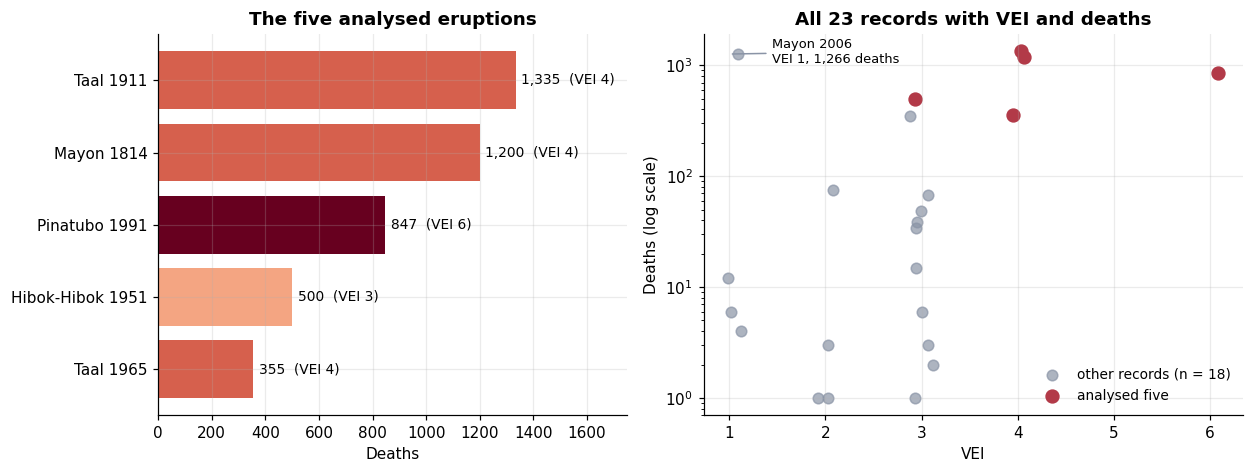

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NAVY, BLUE, SKY, GOLD, RED, GREY = "#0A2540", "#1565C0", "#4FC3F7", "#E0A030", "#B23A48", "#8A94A6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
})

import numpy as np
rng = np.random.default_rng(7)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})

# Left: the five analysed eruptions
t = top5.assign(label=top5.Volcano + " " + top5.Year.astype(str)).sort_values("Deaths")
vei_colors = {3: "#F4A582", 4: "#D6604D", 6: "#67001F"}
axes[0].barh(t.label, t.Deaths, color=[vei_colors[v] for v in t.VEI])
for y, (d, v) in enumerate(zip(t.Deaths, t.VEI)):
    axes[0].text(d + 20, y, f"{d:,}  (VEI {v})", va="center", fontsize=9)
axes[0].set_xlim(0, 1750)
axes[0].set_title("The five analysed eruptions")
axes[0].set_xlabel("Deaths")

# Right: all records that have both values
jit = rng.uniform(-0.12, 0.12, len(clean))
in_top = clean.index.isin(ranked.head(5).index)
axes[1].scatter(clean.VEI[~in_top] + jit[~in_top], clean.Deaths[~in_top], s=48, color=GREY, alpha=0.7, label="other records (n = 18)")
axes[1].scatter(clean.VEI[in_top] + jit[in_top], clean.Deaths[in_top], s=70, color=RED, label="analysed five")
m = clean[(clean.Volcano == "Mayon") & (clean.Year == 2006)].iloc[0]
axes[1].annotate("Mayon 2006\nVEI 1, 1,266 deaths", (m.VEI, m.Deaths), textcoords="offset points",
                 xytext=(28, -6), fontsize=8.5, arrowprops=dict(arrowstyle="-", color=GREY))
axes[1].set_yscale("log")
axes[1].set_xlabel("VEI"); axes[1].set_ylabel("Deaths (log scale)")
axes[1].set_xticks([1, 2, 3, 4, 5, 6])
axes[1].set_title("All 23 records with VEI and deaths")
axes[1].legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Results

```{figure} ../images/volcano-infographic.jpg
:width: 70%
:align: center
:alt: Infographic of five Philippine volcanic eruptions

Infographic: VEI, eruption type, and death toll for Pinatubo (1991), Mayon (1814), Taal (1911), Hibok-Hibok (1951), and Taal (1965).
```

**Key findings**

1. **VEI alone does not predict mortality.** The correlation is weak (r = 0.19, r² ≈ 0.035), so explosivity
   explains only a few percent of the variation in deaths. Hibok-Hibok (VEI 3, 500 deaths) killed more people than
   Taal 1965 (VEI 4, 355 deaths).
2. **Secondary hazards and exposure drive casualties.** From the report's context: lahars caused roughly 60% of
   Pinatubo's deaths, Taal 1911 affected an estimated 500,000 people within 15 km, and Mayon 1814 struck at night,
   limiting evacuation.
3. **Preparedness saves lives.** The 1991 Pinatubo eruption was the century's largest (VEI 6) yet caused fewer
   deaths than two VEI 4 events (Taal 1911 and Mayon 1814), and modern PHIVOLCS monitoring and evacuations are credited with saving thousands.

**How sensitive is r to which eruptions are chosen?**

In [4]:
by_deaths = clean.sort_values("Deaths", ascending=False).head(5)
sets = [
    ("As analysed: top 5 by VEI (ties by deaths)", ranked.head(5)),
    ("Top 5 ranked by deaths instead", by_deaths),
    ("All records with both values", clean),
]
pd.DataFrame([{"selection": name, "n": len(d), "r (VEI, Deaths)": round(d["VEI"].corr(d["Deaths"]), 2)}
              for name, d in sets])

,selection,n,"r (VEI, Deaths)"
0,As analysed: top 5 by VEI (ties by deaths),5,0.19
1,Top 5 ranked by deaths instead,5,-0.21
2,All records with both values,23,0.38


The conclusion (*VEI is at best a weak-to-moderate predictor of deaths*) holds across all three selections, but
the exact number moves from −0.21 to 0.38, which is expected with so few points.

## 6. Data Science Concepts Demonstrated

| Concept | Where it appears |
|---|---|
| **Data cleaning** | Renaming, profiling missingness, listwise deletion on the two analysis variables |
| **Variable selection** | Choosing an intensity measure (VEI) and a consequence measure (deaths) and justifying both |
| **Correlation & effect size** | Pearson r and r² (variance explained) |
| **Small-sample caution** | Explicit statement that five points are illustrative, not conclusive |
| **Confounding / lurking variables** | Population exposure, hazard type, timing, preparedness |
| **Data visualisation** | Bar chart with VEI as fill, correlation plot, and infographic design |
| **Communicating uncertainty** | Notes on limits of the dataset and inference |
| **Reproducible reporting** | R Markdown → PDF with code, tables, and figures together |

## 7. Limitations & Next Steps

- **Selection rule and labelling.** The R code ranks by VEI (ties by deaths), so the set is the *five
  highest-VEI eruptions with recorded deaths*, not the five deadliest. Ranking by deaths instead brings in
  Mayon 2006 (VEI 1, 1,266 deaths). Either rename the set or re-rank, and state the rule on the infographic.
- **Selecting on VEI restricts its range** and can mask the relationship; using all 23 records is more defensible.
- **Missing data is not random.** Sixteen eruptions have no death count; unrecorded, zero, and unknown are
  different things. Dropping them biases the sample toward well-documented, deadlier events.
- **Small n and no uncertainty interval.** Add a bootstrap confidence interval for r (see the coffee-income project) and a rank-based measure (Spearman).
- **Model the drivers.** Add population within 15 km, eruption type/agent, and time of day, then fit a count model
  (e.g. Poisson or negative binomial) for deaths.
- **Historical bias.** Older events are reported differently from modern ones; include era as a variable.
- **Interactive map.** Plot eruptions by location and VEI with population-exposure layers.